In [1]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 11.6 MB/s  0:00:00 12.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 16.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 10.9 MB/s  0:00:00 11.6 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

clientes = pd.read_parquet("data/clean/clientes_modelo.parquet")
print(clientes.shape)

tasa = clientes["impago_mes_siguiente"].mean()
print(f"Tasa de impago: {tasa:.1%}")

(29909, 25)
Tasa de impago: 22.1%


In [4]:
def tasa_por(columna):
    return (
        clientes.groupby(columna, observed=True)["impago_mes_siguiente"]
        .agg(clientes="size", tasa_impago="mean")
        .round(3)
    )

def dibujar(tabla, titulo, eje_x):
    ax = tabla["tasa_impago"].plot(kind="bar", color="#555555", figsize=(8, 4))
    ax.axhline(tasa, color="black", linestyle="--", label=f"media ({tasa:.0%})")
    ax.set(title=titulo, xlabel=eje_x, ylabel="tasa de impago")
    ax.yaxis.set_major_formatter("{x:.0%}")
    ax.legend()
    plt.show()

                 clientes  tasa_impago
estado_pago_sep                       
-2.0                 2748        0.132
-1.0                 5670        0.168
 0.0                14696        0.128
 1.0                 3673        0.340
 2.0                 2660        0.691
 3.0                  322        0.758
 4.0                   76        0.684
 5.0                   26        0.500
 6.0                   10        0.600
 7.0                    9        0.778
 8.0                   19        0.579


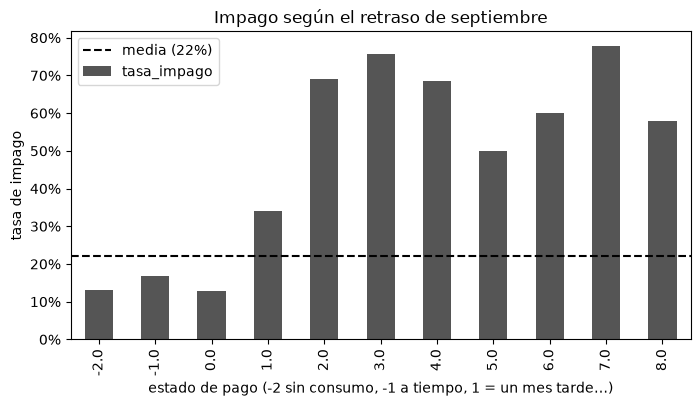

In [5]:
t = tasa_por("estado_pago_sep")
print(t)
dibujar(t, "Impago según el retraso de septiembre", "estado de pago (-2 sin consumo, -1 a tiempo, 1 = un mes tarde…)")